# Data Frame 실습

## 1. Data Frame 기초

### Library 설치
- Library는 한 번만 설치하면 됨

In [ ]:
!pip install pandas
!pip install openpyxl
!pip install matplotlib
!pip install wordcloud

### Pandas로 Data Frame 만들기

In [ ]:
import pandas as pd

In [ ]:
df_list = [["2023300201", "홍길동", 100, 80],
           ["2024123456", "홍길영", 70, 56],
           ["2025123457", "홍길일", 65, 32],
           ["2022123458", "홍길이", 27, 75],
           ["2023123459", "홍길삼", 92, 65],
           ["2024123460", "홍길사", 85, 30],
           ["2025123461", "홍길오", 28, 22],
           ["2026123462", "홍길육", 36, 21],
           ["2022123463", "홍길칠", 42, 25],
           ["2023123464", "홍길팔", 56, 30],
           ["2025123465", "홍길구", 98, 35],
           ["2021123466", "홍길둘", 80, 40]]
print(df_list)
print(type(df_list))

In [ ]:
# pd.DataFrame(데이터 list, index = 행 이름 list, columx = 열 이름 list)
df = pd.DataFrame(df_list,
                  index=["1번 학생", "2번 학생", "3번 학생", "4번 학생", "5번 학생", "6번 학생",
                         "7번 학생", "8번 학생", "9번 학생", "10번 학생", "11번 학생", "12번 학생"],
                  columns=["학번", "이름", "대학영어", "미분적분학"])
print(df)
print(type(df))

### 행/열 갯수 조회

In [ ]:
print(df.shape)

### 행(row) 조회

In [ ]:
score_eng = df["대학영어"]
print(score_eng)
print(type(score_eng))
score_eng_list = score_eng.tolist()
print(score_eng_list)
print(type(score_eng_list))

In [ ]:
score_result_1 = df.loc["1번 학생"]
print(score_result_1)
print(type(score_result_1))
score_result_1_list = score_result_1.tolist()
print(score_result_1_list)
print(type(score_result_1_list))

In [ ]:
score_result_1 = df.loc[["1번 학생"]]
print(score_result_1)
print(type(score_result_1))

In [ ]:
score_result_multi_1 = df.loc[["1번 학생", "8번 학생", "10번 학생"]]
print(score_result_multi_1)

In [ ]:
score_result_multi_2 = df.loc["1번 학생":"8번 학생"]  # 주의: 여기에서는 미만이 아님. start부터 end까지
print(score_result_multi_2)

In [ ]:
score_result_not_2 = df.loc[df.index != "2번 학생"]
print(score_result_not_2)

### 열(column) 조회

In [ ]:
score_calculus = df.loc[:,"미분적분학"]
print(score_calculus)
print(type(score_calculus))
score_calculus_list = score_calculus.tolist()
print(score_calculus_list)
print(type(score_calculus_list))

In [ ]:
score_calculus = df.loc[:,["미분적분학"]]
print(score_calculus)
print(type(score_calculus))

In [ ]:
score_name = df.loc[:, "이름":"미분적분학"]
print(score_name)
print(type(score_name))

In [ ]:
score_not_eng = df.loc[:, df.columns != "대학영어"]
print(score_not_eng)
print(type(score_not_eng))

### 행, 열 조회

In [ ]:
score_2_cal = df.loc["2번 학생", "미분적분학"]
print(score_2_cal)
print(type(score_2_cal))

In [ ]:
score_multi = df.loc[["2번 학생", "4번 학생"], ["학번", "미분적분학"]]
print(score_multi)
print(type(score_multi))

### index로 행, 열 조회

In [ ]:
score_2_idx = df.iloc[1,:]
print(score_2_idx)
print(type(score_2_idx))

In [ ]:
score_2_idx = df.iloc[[1],:]
print(score_2_idx)
print(type(score_2_idx))

In [ ]:
score_2_idx_score = df.iloc[1, 3] # Row 1번째(0 기준), Column 3번째(0 기준)
print(score_2_idx_score) 
print(type(score_2_idx_score))

## 2. 엑셀/CSV 파일 데이터 분석

In [1]:
import pandas as pd
from collections import Counter

import matplotlib
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

### 엑셀/CSV 파일 불러오기

In [2]:
# Excel 파일 열기
raw_df = pd.ExcelFile("./NewsResult_20260815-20261115.xlsx").parse("sheet")

C:\Users\HANENCIA\miniconda3\envs\common\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [ ]:
# CSV 파일 열기
raw_df = pd.read_csv("./NewsResult_20260815-20261115_csv.csv")

### Data Frame 보기

In [3]:
# 첫 5행 보기
raw_df.head(1)

,뉴스 식별자,일자,언론사,기고자,제목,통합 분류1,통합 분류2,통합 분류3,사건/사고 분류1,사건/사고 분류2,사건/사고 분류3,인물,위치,기관,키워드,특성추출(가중치순 상위 50개),본문,URL,분석제외 여부
0,1.100401e+06,20261113,동아일보,배미정,"연세대, ‘심리학기반 조직코칭 전문가 양성과정’ 1기 모집",IT_과학>IT_과학일반,사회>사회일반,NaN,NaN,NaN,NaN,NaN,한국코칭심리학회,"한국코칭심리학회,연세대학교,연세대","연세대,심리학,조직,코칭,전문가,양성,모집,강화,AI,시대,조직,리더십,심리학,이론...","심리학,코칭,구성원,연세대,전문가,한국코칭심리학회,ai,교수진,연세대학교,이수,한광...",연세대학교 심리과학이노베이션대학원이 ‘심리학기반 조직코칭 전문가 양성과정’ 1기 수...,https://www.donga.com/news/Society/article/all...,NaN


In [4]:
# 마지막 5행 보기
raw_df.tail(1)

,뉴스 식별자,일자,언론사,기고자,제목,통합 분류1,통합 분류2,통합 분류3,사건/사고 분류1,사건/사고 분류2,사건/사고 분류3,인물,위치,기관,키워드,특성추출(가중치순 상위 50개),본문,URL,분석제외 여부
269,1.101001e+06,20260816,한겨레,이유진 기자,“페미니즘이 도달하고자 하는 곳은 공존” [.txt],사회>교육_시험,문화>출판,문화>학술_문화재,NaN,NaN,NaN,"조한혜정,이철,당시,나임윤경,나임,김현미","미국,페다,양평원,한국,저도,압구정동,개진","경향신문,한국양성평등교육진흥원,연세대,한겨레신문사,철도공사,코레일,한겨레,문화학협동...","페미니즘,도달,공존,txt,학생들,20대,권력,자신,기득권,선생,방법론,결국,페미니...","가해자,연세대,문화학협동과정,에브리타임,나임,한국,코레일,여성들,학생들,기득권,문화...","“학생들은 ‘20대인 우리한테 무슨 권력이 있어요?’라고 말하지만, 그런 자신이 어...",https://www.hani.co.kr/arti/culture/book/12730...,NaN


In [5]:
# 처음부터 10번째(사람 기준) 행까지 보기
raw_df[:10]

,뉴스 식별자,일자,언론사,기고자,제목,통합 분류1,통합 분류2,통합 분류3,사건/사고 분류1,사건/사고 분류2,사건/사고 분류3,인물,위치,기관,키워드,특성추출(가중치순 상위 50개),본문,URL,분석제외 여부
0,1.100401e+06,20261113,동아일보,배미정,"연세대, ‘심리학기반 조직코칭 전문가 양성과정’ 1기 모집",IT_과학>IT_과학일반,사회>사회일반,NaN,NaN,NaN,NaN,NaN,한국코칭심리학회,"한국코칭심리학회,연세대학교,연세대","연세대,심리학,조직,코칭,전문가,양성,모집,강화,AI,시대,조직,리더십,심리학,이론...","심리학,코칭,구성원,연세대,전문가,한국코칭심리학회,ai,교수진,연세대학교,이수,한광...",연세대학교 심리과학이노베이션대학원이 ‘심리학기반 조직코칭 전문가 양성과정’ 1기 수...,https://www.donga.com/news/Society/article/all...,NaN
1,1.100751e+06,20261113,아시아투데이,NaN,"종로구, 통합돌봄 연계 의료기관 5곳→30곳 확대",사회>의료_건강,사회>여성,NaN,NaN,NaN,NaN,NaN,"종로구,서울,서울숭인병원","안암병원,세브란스병원,로이병원,서울적십자병원,여의도성모병원,종로구청장,중앙보훈병원,...","종로구,통합,5곳,연계,의료,기관,30곳,확대,아시아투데이,박아람,서울,종로구,퇴원...","종로구,의료기관,돌봄,5곳,관외,박아람,유찬종,아시아투데이,30곳,여의도성모병원,로...",아시아투데이 박아람 기자 = 서울 종로구가 퇴원환자의 빠른 회복과 안정적인 재가 복...,https://www.asiatoday.co.kr/kn/view.php?key=20...,NaN
2,1.100101e+06,20261113,경향신문,백승찬 선임기자 myungworry@kyunghyang.com,"‘궤도’ 번역한 송예슬씨, 제20회 유영번역상 영예",문화>학술_문화재,문화>출판,문화>미술_건축,NaN,NaN,NaN,"유영번,민은경,이형진,이석구,강태경,유영,송예슬,조규형",상패,"숙명여대,고려대,이화여대,연세대학교,심사위원회,연세대,에버렛,영어영문학연구소,서울대...","궤도,번역,송예슬씨,영예,유영번,역상,번역가,송예슬,유영번,역상,수상자,선정,유영학...","송예슬,유영번역상,연세대,영문학,수상자,역상,번역가,유영번,중연회실,본심사,송예슬씨...",번역가 송예슬씨가 올해 유영번역상 수상자로 선정됐다.\n\n유영학술재단은 제20회 ...,https://www.khan.co.kr/article/202611131412001,NaN
3,1.100501e+06,20261113,문화일보,전세원,"“퇴원 후에도 돌봄은 이어진다” 종로구, 통합돌봄 연계 의료기관 30곳으로 확대",사회>의료_건강,사회>장애인,NaN,NaN,NaN,NaN,NaN,"종로구,서울,종로구립,서울숭인병원","안암병원,세브란스병원,로이병원,서촌,서울적십자병원,여의도성모병원,서울대병원,종로구청...","퇴원,종로구,통합,30곳,연계,의료,기관,확대,서울대병원,강북삼성병원,관내,참여,국...","종로구,의료기관,박노수미술관,국립중앙의료원,관외,강북삼성병원,서울대학교병원,돌봄,6...",서울대병원 강북삼성병원 등 관내 6개소\n국립중앙의료원 포함 관외 24개소 참여\n...,https://www.munhwa.com/article/11630999?ref=kpf,NaN
4,1.100801e+06,20261113,조선일보,조선일보,[사설] 서울 학내 시위로 5 18 보상금 노렸던 법무장관 후보자,정치>정치일반,NaN,NaN,사회>사회갈등>시위,NaN,NaN,이용철,"서울,광주","정부,연세대학교,청와대,법무부,법원,유공,광주,보상심의위","시위,서울,학내,5,법무,장관,후보자,이용철,법무부,장관,후보자,5,광주,민주,운동...","보상금,후보자,광주,민주화,유공자,청와대,서울,법무비서관,비서관,보상법,국회의원,시...",이용철 법무부 장관 후보자가 2004년 광주 5 18 민주화운동 보상금 신청을 했다...,https://www.chosun.com/opinion/editorial/2026/...,NaN
5,1.100611e+06,20261112,서울신문,양승현 리포터,"제이인츠바이오, 30억원 연구지원 기반 KRAS 표적항암제 개발 본격화",IT_과학>과학,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"ASCO,EG,IN,KR,BIO,중소벤처기업부,EGFR,정부,연세대학교,미국임상종양...","제이인츠바이오,30억,연구지원,KRAS,표적,항암제,본격화,스케일업,팁스,지원,환자...","제이인츠바이오,kras,단백질,팁스,ai,스케일업,egfr,항암제,유전자,후보물질,...",-스케일업 팁스 3년 지원 환자 데이터와 자체 AI 신약개발 플랫폼 ‘JIN-NOV...,https://www.seoul.co.kr/news/newsView.php?id=2...,NaN
6,1.100201e+06,20261112,국민일보,이누리,농협 강호동 회장 연세대서 ‘농심천심의 날’ 특강,경제>경제일반,NaN,NaN,NaN,NaN,NaN,강호동,"서울,서대문구,농축산","농협,연세대학교,NH농협은행,연세대,농협중앙회장,농협중앙회","농협,강호동,회장,연세대,농심천심,특강,농협중앙회,농업인,연세대학교,서울,서대문구,...","강호동,농심천심,농업인,서대문구,서울,연세대,협동조합,농축산물,특강자,농협중앙회장,...",농협중앙회는 11일 ‘농업인의 날’을 맞아 서울 서대문구 연세대학교에서 농업 농촌의...,https://www.kmib.co.kr/article/20261111501991,NaN
7,1.100701e+06,20261112,세계일보,한윤종,"농협, 대학생들과 농업의 미래 논의 연세대서 농심천심 행사",경제>서비스_쇼핑,지역>충남,지역>부산,NaN,NaN,NaN,강호동,"서울,서대문구,영양,대한민국,농축산","목우촌,농협,연세대학교,NH농협은행,연세대,농협중앙회장,농협경제지주,농협중앙회,경기농협","농협,대학생,농업,미래,논의,연세대,농심천심,행사,서울,서대문구,연세대학교,농심천심...","농심천심,농협,농협중앙회,농산물,강호동,연세대학교,대학생,학생들,농심천심운동,청년층...",11일 서울 서대문구 연세대학교에서 열린 '농심천심의 날' 행사에서 강호동 농협중앙...,https://www.segye.com/newsView/20261112503658,NaN
8,1.100801e+06,20261112,조선일보,조선일보,4분기 국가고객만족도 1위 기업 인증식,경제>서비스_쇼핑,NaN,NaN,NaN,NaN,NaN,"최정호,이강영,박선현,홍준호,박성중,이은미,심창섭,박성민,조신형,정상혁,김재관,김국...","송현도,중구,서울","KB국민카드,삼성화재,세브란스병원,KB국민은행,조선일보,광주은행,DB손해보험,신한은...","인증식,국가,고객,만족도,기업,11일,롯데호텔,서울,중구,국가고객만족도,국가,고객,...","부사장,대표이사,이범욱,박선현,부행장,김재관,국가고객만족도,김국진,이강영,이재용,연...",11일 오전 서울 중구 롯데호텔에서 열린 ’2026년도 4분기 국가고객만족도(NCS...,https://www.chosun.com/economy/economy_general...,NaN
9,1.100901e+06,20261111,중앙일보,이정은,포브스코리아 ‘2026 AI 50 서미트‘ 연세대서 개최,IT_과학>과학,경제>경제일반,NaN,NaN,NaN,NaN,"강정석,즈윅,서아란,오은송,윤동섭,김재승,허윤홍","서미트,아시아,서울","산업별,에이젠글로벌,연세대학교,연세대,모빌테크,GS건설,딥인사이트","포브스코리아,AI,서미트,연세대,개최,포브스코리아,인공,AI,혁신,기업,비전,공유,...","ai,연세대,포브스코리아,즈윅,100m,서아란,챗봇,허윤홍,강정석",포브스코리아가 국내 인공지능(AI) 혁신 기업들의 기술력과 비전을 공유하는 자리를 ...,https://www.joongang.co.kr/article/25477731,NaN


In [6]:
# Column 이름 보기
raw_df.columns

Index(['뉴스 식별자', '일자', '언론사', '기고자', '제목', '통합 분류1', '통합 분류2', '통합 분류3',
       '사건/사고 분류1', '사건/사고 분류2', '사건/사고 분류3', '인물', '위치', '기관', '키워드',
       '특성추출(가중치순 상위 50개)', '본문', 'URL', '분석제외 여부'],
      dtype='object')

### 데이터 추출

In [7]:
# 키워드 Column만 추출
keyword = raw_df['키워드']
print(keyword)

0      연세대,심리학,조직,코칭,전문가,양성,모집,강화,AI,시대,조직,리더십,심리학,이론...
1      종로구,통합,5곳,연계,의료,기관,30곳,확대,아시아투데이,박아람,서울,종로구,퇴원...
2      궤도,번역,송예슬씨,영예,유영번,역상,번역가,송예슬,유영번,역상,수상자,선정,유영학...
3      퇴원,종로구,통합,30곳,연계,의료,기관,확대,서울대병원,강북삼성병원,관내,참여,국...
4      시위,서울,학내,5,법무,장관,후보자,이용철,법무부,장관,후보자,5,광주,민주,운동...
                             ...                        
265    아이스테이징아시아,디지털,피지컬,AI,디지털,트윈,교육,의료,로봇,혁신,인재,강원,...
266    숲과,한겨레신문,AI,교통,해법,재단,법인,숲과,데이터,이동,AI,교통,해결,데이터...
267    오픈AI,세계,실증,지원,한국,연세대,포함,아시아투데이,김영진,오픈AI,OpenAI...
268    YS,시절,위기,해결,제임스,레이니,주한,주한,대사,별세,해결,김영삼,정부,시절,위...
269    페미니즘,도달,공존,txt,학생들,20대,권력,자신,기득권,선생,방법론,결국,페미니...
Name: 키워드, Length: 270, dtype: object


In [ ]:
keyword = raw_df.iloc[:,14]
print(keyword)

In [8]:
# 키워드 Column만 추출해서 list로 변환
keyword_lst = raw_df['키워드'].tolist()
# keyword_lst = keyword.tolist()
print(keyword_lst)
print(len(keyword_lst))

['연세대,심리학,조직,코칭,전문가,양성,모집,강화,AI,시대,조직,리더십,심리학,이론,결합,코칭,실습,연세대,심리학,교수진,참여,조직코칭심리사,지원,자격,취득,연세대학교,심리,과학,이노베이션,대학원,심리학,조직,코칭,전문가,양성,수강,모집,인공지능,AI,자동화,확산,조직,업무,환경,변화,심리학,이해,바탕,구성원,성장,조직,성과,코칭,전문가,양성,마련,교수진,연세대,심리학,전문가들,코칭,심리학,분야,전문가,교육,참여,AI,정보,의사결정,지원,시대,구성원,심리,이해,신뢰,협력,리더,역량,중요,시대,변화,대응,심리학,과학,이론,현장,실제,조직,활용,코칭,기법,결합,특징,발달심리학,성격심리학,인지심리학,조직심리학,학습심리학,심리학,분야,성과,토대,구성원,행동,동기,이해,조직,갈등,해결,소통,개선,리더십,적용,설계,교육과정,모듈,40시간,구성,심리학,코칭,핵심,인간,사고,행동,조직문화,리더십,구성원,동기,성격,그룹코칭,주제,이론,강의,코칭,모델,실습,병행,교육,현장,실제,조직,적용,한국코칭심리학회,조직코칭심리사,자격,취득,교육프로그램,인정,교육,수료자,자격,취득,요건,교육,이수,충족,한국코칭심리학회,수련,감독자,지도하,실습,코칭,온라인,평가,자격,심사,자격,취득,도전,교육,대상,기업,리더,인사,조직개발,HR,공공,재직자,민간,기관,사내,코치,교육,리더십,역할,조직,코칭,분야,경력,확장,실무자,지원,심리과학이노베이션대학원장,한광희,연세대,심리,과학,이노베이션,대학원장,AI,업무,시대,사람,마음,이해,구성원,자발적,성장,협력,리더십,중요,조직,소통,갈등,해결,어려움,리더들,구성원,잠재력,조직,변화,주도,실질,도움', '종로구,통합,5곳,연계,의료,기관,30곳,확대,아시아투데이,박아람,서울,종로구,퇴원환자,회복,안정적,복귀,통합,연계,의료,기관,5곳,30곳,확대,종로구,참여,의료,기관,서울대학교병원,강북삼성병원,서울적십자병원,로이병원,리움한방병원,서울숭인병원,6곳,참여,구민,이용,국립중앙의료원,여의도성모병원,중앙보훈병원,고려대학교,안암병원,연세대학교,세브란스병원,관외,포함

In [9]:
# 단어를 하나의 리스트에 합치기
# ["단어1-1, 단어1-2", "단어2-1, 단어2-2", ...] => ["단어1-1", "단어1-2", "단어2-1", "단어2-2", ...]
keyword_vocalist = []
for keyword in keyword_lst:
    for voca in keyword.split(","):
        keyword_vocalist.append(voca)

In [10]:
print(keyword_vocalist)
print(len(keyword_vocalist))

['연세대', '심리학', '조직', '코칭', '전문가', '양성', '모집', '강화', 'AI', '시대', '조직', '리더십', '심리학', '이론', '결합', '코칭', '실습', '연세대', '심리학', '교수진', '참여', '조직코칭심리사', '지원', '자격', '취득', '연세대학교', '심리', '과학', '이노베이션', '대학원', '심리학', '조직', '코칭', '전문가', '양성', '수강', '모집', '인공지능', 'AI', '자동화', '확산', '조직', '업무', '환경', '변화', '심리학', '이해', '바탕', '구성원', '성장', '조직', '성과', '코칭', '전문가', '양성', '마련', '교수진', '연세대', '심리학', '전문가들', '코칭', '심리학', '분야', '전문가', '교육', '참여', 'AI', '정보', '의사결정', '지원', '시대', '구성원', '심리', '이해', '신뢰', '협력', '리더', '역량', '중요', '시대', '변화', '대응', '심리학', '과학', '이론', '현장', '실제', '조직', '활용', '코칭', '기법', '결합', '특징', '발달심리학', '성격심리학', '인지심리학', '조직심리학', '학습심리학', '심리학', '분야', '성과', '토대', '구성원', '행동', '동기', '이해', '조직', '갈등', '해결', '소통', '개선', '리더십', '적용', '설계', '교육과정', '모듈', '40시간', '구성', '심리학', '코칭', '핵심', '인간', '사고', '행동', '조직문화', '리더십', '구성원', '동기', '성격', '그룹코칭', '주제', '이론', '강의', '코칭', '모델', '실습', '병행', '교육', '현장', '실제', '조직', '적용', '한국코칭심리학회', '조직코칭심리사', '자격', '취득', '교육프로그램', '인정', '교육', '수료자', '자격', '취득', '요건

### 불용어(Stop Words)제거
- 불용어(Stop word): 분석에 방해(noise)가 되는 단어
- 예: the, a, an, is, I, my 등과 같이 문장을 구성하는 필수 요소지만 문맥적으로 큰 의미가 없는 단어
- 텍스트에 빈번하게 나타나기 때문에 중요한 단어로 인지될 수 있으나 실질적으로는 중요하지 않음 => 분석에 노이즈가 되므로 제거해야 함

In [15]:
stop_words_list = ['방안', '연세대', '연세대학교']
# keyword_vocalist를 전부 순회(반복)한 후 stop_words_list에 없는 단어만 골라서 리스트를 만들기
keyword_vocalist = list(filter(lambda x: x not in stop_words_list, keyword_vocalist))
'''
참고: 위 코드는 아래 for문과 동일함

keyword_vocalist = []

for x in keyword_vocalist:
    if x not in stop_words_list:
        keyword_vocalist.append(x)
'''
print(len(keyword_vocalist))

53863


### 단어 빈도수 세기

In [18]:
# list에 있는 단어 빈도수를 세어서 상위 n개를 내림차순으로 (단어, 빈도수)의 형태로 리스트 만들기
word_count = Counter(keyword_vocalist).most_common(1000)

In [19]:
print(word_count)
print(type(word_count))
print(type(word_count[0]))

[('AI', 507), ('교수', 284), ('지원', 225), ('활용', 216), ('대학', 215), ('서울', 190), ('참여', 187), ('교육', 176), ('기업', 169), ('사업', 166), ('현장', 162), ('진행', 160), ('지역', 158), ('정책', 151), ('협력', 147), ('한국', 147), ('분야', 138), ('임상', 134), ('사회', 131), ('계획', 127), ('세계', 127), ('운영', 126), ('환자', 125), ('산업', 125), ('예정', 123), ('안전', 122), ('행사', 121), ('중심', 120), ('국제', 120), ('개최', 120), ('의료', 117), ('도서관', 117), ('활동', 116), ('경험', 114), ('마련', 112), ('확대', 112), ('결과', 109), ('변화', 108), ('미국', 104), ('대회', 103), ('경찰', 103), ('데이터', 102), ('환경', 101), ('대상', 101), ('생산', 101), ('정보', 100), ('주제', 100), ('프로그램', 100), ('대표', 100), ('남성', 100), ('확인', 99), ('미래', 98), ('논의', 97), ('혁신', 97), ('성장', 95), ('글로벌', 95), ('평가', 93), ('기관', 93), ('가능', 93), ('공동', 92), ('추진', 92), ('발전', 90), ('시장', 90), ('강화', 88), ('양자', 88), ('이용', 87), ('바이오', 87), ('센터', 87), ('공유', 86), ('서비스', 85), ('연결', 85), ('청년', 85), ('구축', 84), ('문화', 84), ('인근', 84), ('캠퍼스', 83), ('설명', 82), ('치료', 81), ('시민'

In [ ]:
a = [['a', 'b'], ['c', 'd']
 pd.DataFrame(a)

In [20]:
word_count_df = pd.DataFrame.from_records(word_count, columns=['WORD','COUNT'])

In [21]:
word_count_df

,WORD,COUNT
0,AI,507
1,교수,284
2,지원,225
3,활용,216
4,대학,215
...,...,...
995,야당,10
996,요청,10
997,경위,10
998,20년,10


### 단어/빈도 그래프 그리기

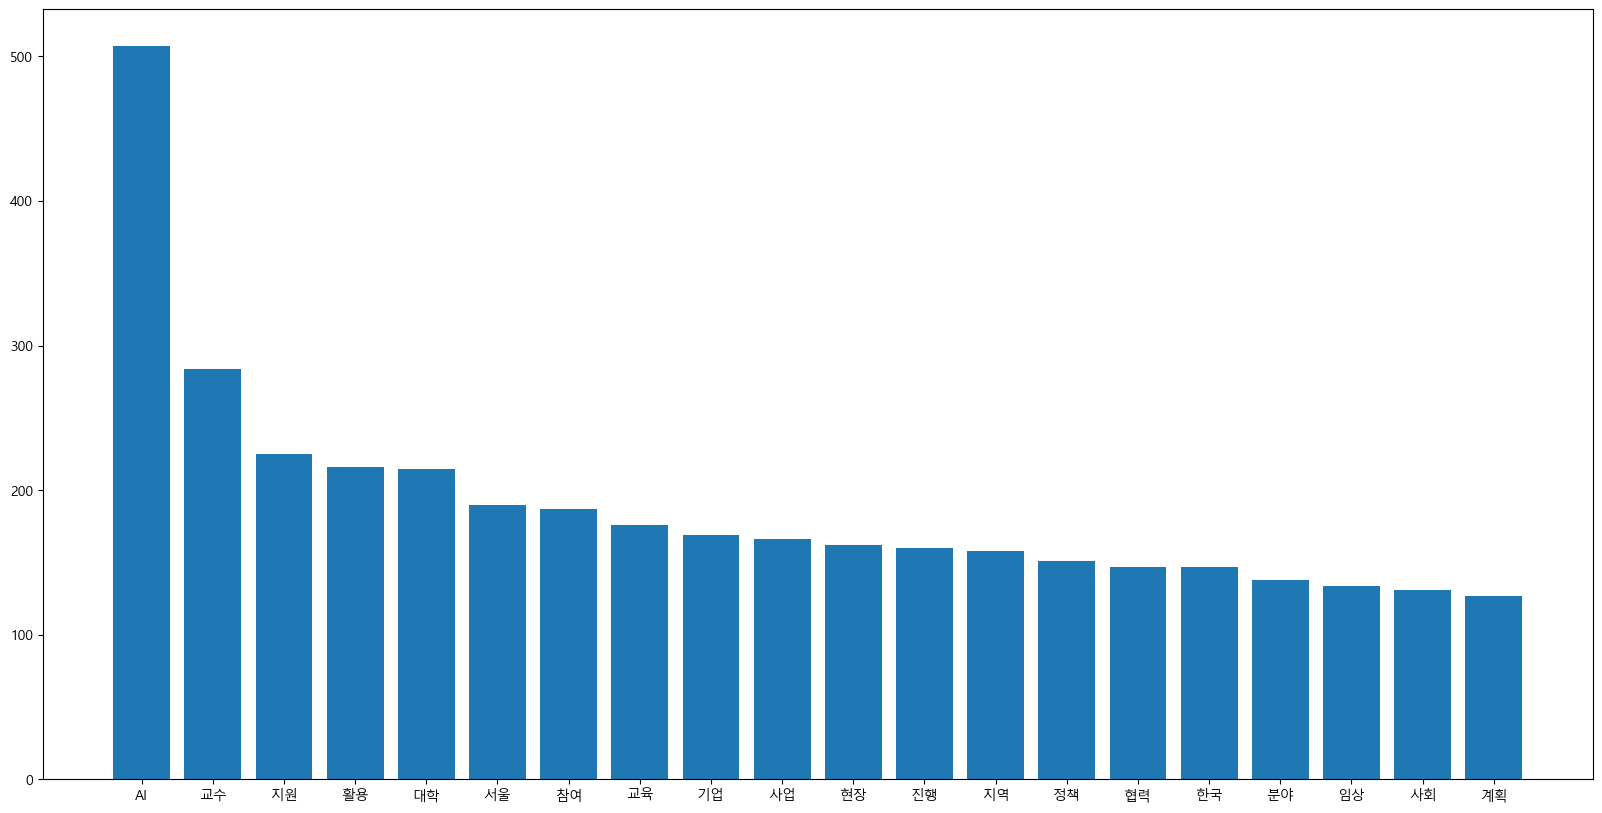

In [41]:
plt.figure(figsize=(20, 10))
plt.rc('font', family='Malgun Gothic')

word_list = word_count_df['WORD'].tolist()[:20]
count_list = word_count_df['COUNT'].tolist()[:20]

plt.bar(word_list, count_list, color='C0')
# Color는 C0, C1, C2, ... 다양하게 있음. 시도해 볼 것)

plt.savefig('빈도.png', bbox_inches='tight', dpi=300, transparent=True)
plt.show()

### 단어/빈도 Data Frame 파일로 저장 (CSV/엑셀)

In [45]:
word_count_df.to_csv('word_count.csv', sep=',', index=False, encoding='utf-8-sig')

In [46]:
word_count_df.to_excel('word_count.xlsx', sheet_name='Sheet1', index=False)

### WordCloud 그리기

In [48]:
import numpy as np
import pandas as pd
from wordcloud import ImageColorGenerator
from wordcloud import WordCloud
from PIL import Image
import matplotlib.pyplot as plt

In [49]:
word_count_df = pd.read_csv('word_count.csv', sep=',', encoding='utf-8')

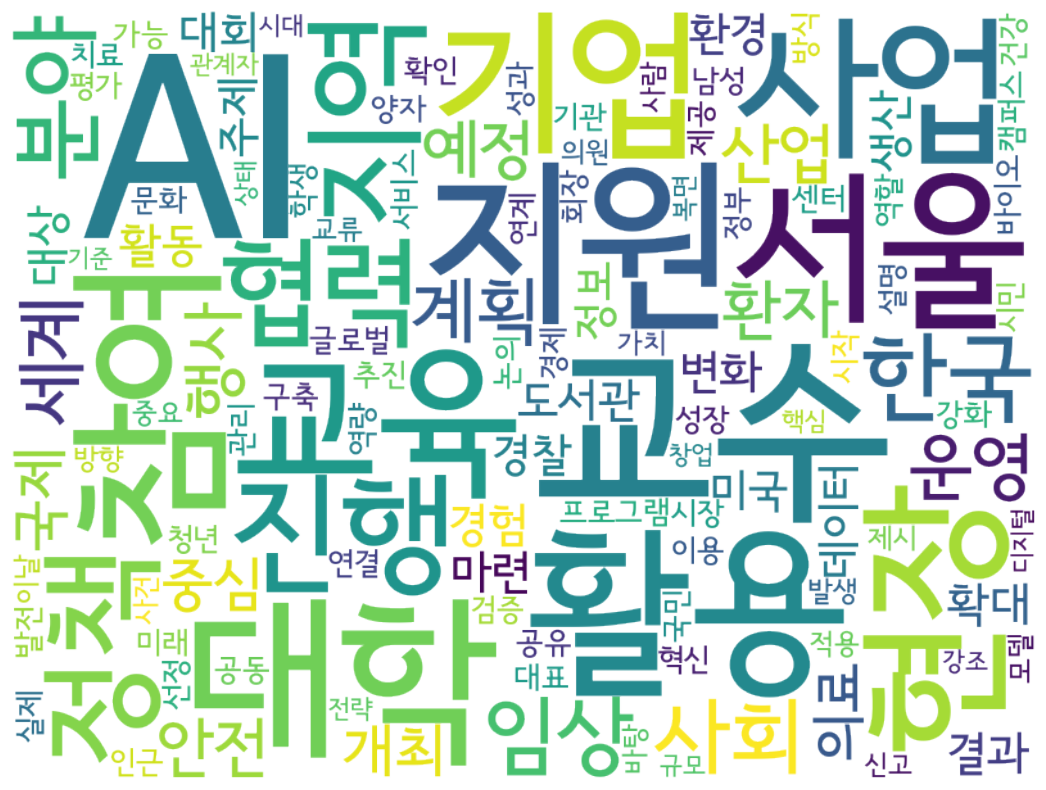

In [54]:
wordcloud = WordCloud(font_path = '08SeoulNamsanB.ttf',
                      width = 800,
                      height = 600,
                      min_font_size = 20,
                      max_font_size = 200,
                      background_color="rgba(255, 255, 255, 0)", mode="RGBA")

wordcloud = wordcloud.generate_from_frequencies(dict(word_count_df.values.tolist()))
plt.figure(figsize=(20, 10))
plt.axis('off')
plt.imshow(wordcloud, interpolation="bilinear")
plt.show()

In [55]:
wordcloud.to_file('Wordcloud.png')

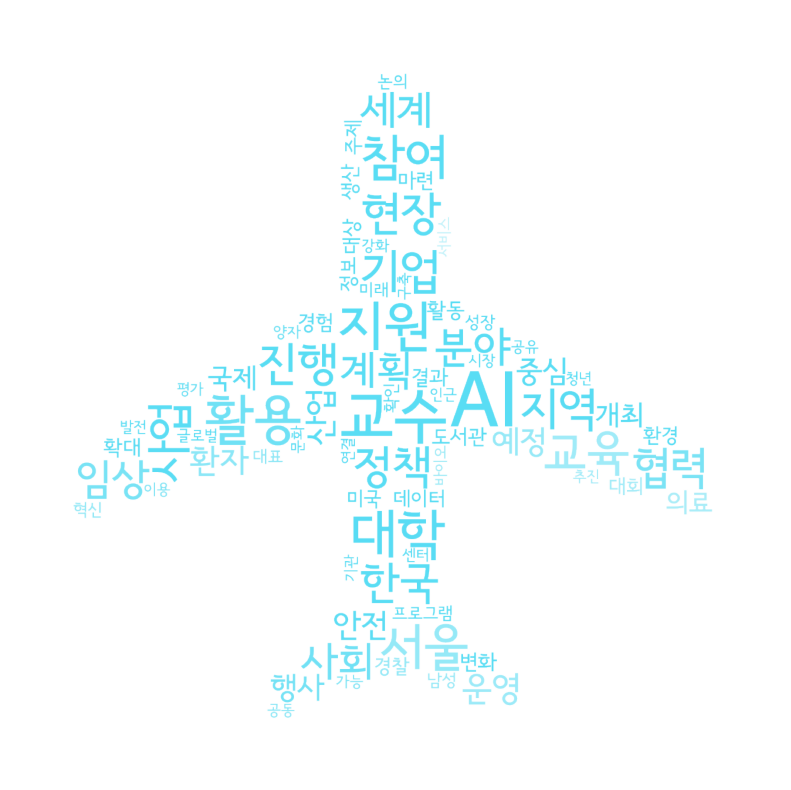

In [70]:
mask_image = 'wordcloud_bg_airplane.png'
mask = np.array(Image.open(mask_image))
mask_colors = ImageColorGenerator(mask)

wordcloud_plane = WordCloud(font_path = '08SeoulNamsanB.ttf',
                            width = 800,
                            height = 600,
                            min_font_size = 20,
                            max_font_size = 100,
                            max_words = 500,
                            background_color="rgba(255, 255, 255, 0)", mode="RGBA",
                            mask = mask)

wordcloud_plane = wordcloud_plane.generate_from_frequencies(dict(word_count_df.values.tolist()))
plt.figure(figsize=(20, 10))
plt.axis('off')
plt.imshow(wordcloud_plane.recolor(color_func = mask_colors), interpolation="bilinear")
plt.show()

In [67]:
wordcloud_plane.to_file('Wordcloud_plane.png')